In [15]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

from wordcloud import WordCloud

# Frequência de palavras

Foi retirado a frquência das palavras mais citadas em títulos e resumos de 40 artigos, totalizando 91 termos, sendo o mais citado "EEG", 35 vezes.

In [16]:
frequencias = {
    "EEG": 35,
    "SYSTEM": 26,
    "BRAIN": 25,
    "DESIGN": 22,
    "COGNITIVE": 18,
    "ELECTRODES": 17,
    "WEARABLE": 17,
    "ANISOTROPIC": 16,
    "CONDUCTIVITY": 16,
    "HEAD": 16,
    "MODELING": 16,
    "APPLICATIONS": 15,
    "MONITORING": 15,
    "SIGNAL": 15,
    "PHANTOM": 14,
    "SYSTEMS": 14,
    "CONTROL": 13,
    "MODEL": 12,
    "LOCALIZATION": 11,
    "REVIEW": 11,
    "SYSTEMATIC": 11,
    "USING": 11,
    "CAN": 10,
    "DEVELOPMENT": 10,
    "DEVICE": 10,
    "ELECTROENCEPHALOGRAPHY": 10,
    "LOAD": 10,
    "RANGE": 10,
    "FUNCTIONAL": 9,
    "TRANSHUMERAL": 9,
    "ACQUISITION": 8,
    "CHANNELS": 8,
    "CIRCUIT": 8,
    "DATA": 8,
    "DEVELOPED": 8,
    "DEVICES": 8,
    "DIPOLE": 8,
    "ELECTROENCEPHALOGRAM": 8,
    "FNIRS": 8,
    "HIGH": 8,
    "MATTER": 8,
    "RAT": 8,
    "SOURCE": 8,
    "WHITE": 8,
    "ACTIVE": 7,
    "INTEGRATION": 7,
    "INTERFACE": 7,
    "ACTUATORS": 6,
    "AREAS": 6,
    "CONFIGURATION": 6,
    "COST": 6,
    "DAYTIME": 6,
    "DISPERSION": 6,
    "ELECTRICAL": 6,
    "ELECTRODE": 6,
    "EQUIPMENT": 6,
    "EQUIVALENT": 6,
    "ERROR": 6,
    "FORWARD": 6,
    "FREQUENCY": 6,
    "HEADBAND": 6,
    "HIGH-DENSITY": 6,
    "IMPEDANCE": 6,
    "LOW-COST": 6,
    "NEUROCOMB": 6,
    "NOVEL": 6,
    "PAPER": 6,
    "POTENTIAL": 6,
    "PRECISE": 6,
    "PRINTED": 6,
    "PROPOSED": 6,
    "PROVIDE": 6,
    "QUALITY": 6,
    "RATIO": 6,
    "REAL-TIME": 6,
    "SCALP": 6,
    "SET": 6,
    "SIGNALS": 6,
    "SIMULATIONS": 6,
    "SOLUTION": 6,
    "SPECTROSCOPY": 6,
    "TESTING": 6,
    "TISSUE": 6,
    "TISSUES": 6,
    "USE": 6,
    "VALIDATION": 6,
    "WIRELESS": 6,
    "BRAIN-COMPUTER": 5,
    "CLINICAL": 5,
    "FLEXIBLE": 5,
    "STRUCTURAL": 5,
}

print(f"Total de termos: {len(frequencias)}")
print("Maior frequência:", max(frequencias.values()))

Total de termos: 91
Maior frequência: 35


# Nuvem de Palavras Básicas

Construção de uma versão básica da nuvem de palavras utilizando a biblioteca wordcloud:

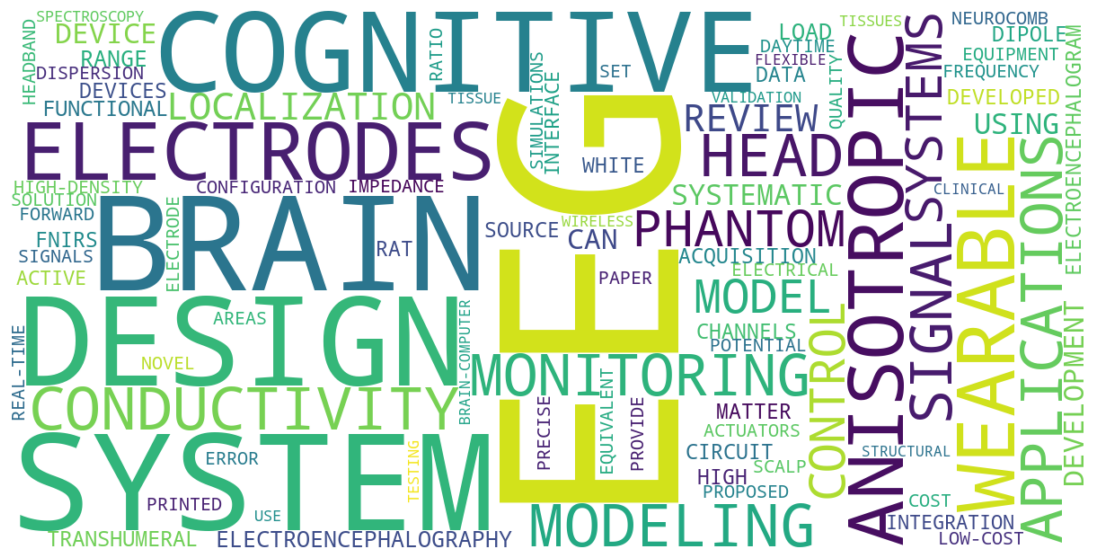

In [17]:
# Nuvem de palavras básica

nuvem_basica = WordCloud(
    width=1200,
    height=600,
    background_color="white",
    max_words=100
).generate_from_frequencies(frequencias)

plt.figure(figsize=(14, 7))
plt.imshow(nuvem_basica, interpolation="bilinear")
plt.axis("off")
plt.savefig("figs/topico_07_02_01.png", dpi=300, bbox_inches="tight", facecolor=plt.gcf().get_facecolor())
plt.show()

# Gráfico de Barras

Construção de gráfico de barras para mostrar as palavras mais frequentes, como alternativa a dificuldade de verificar a ocorrência na nuvem de palavras:

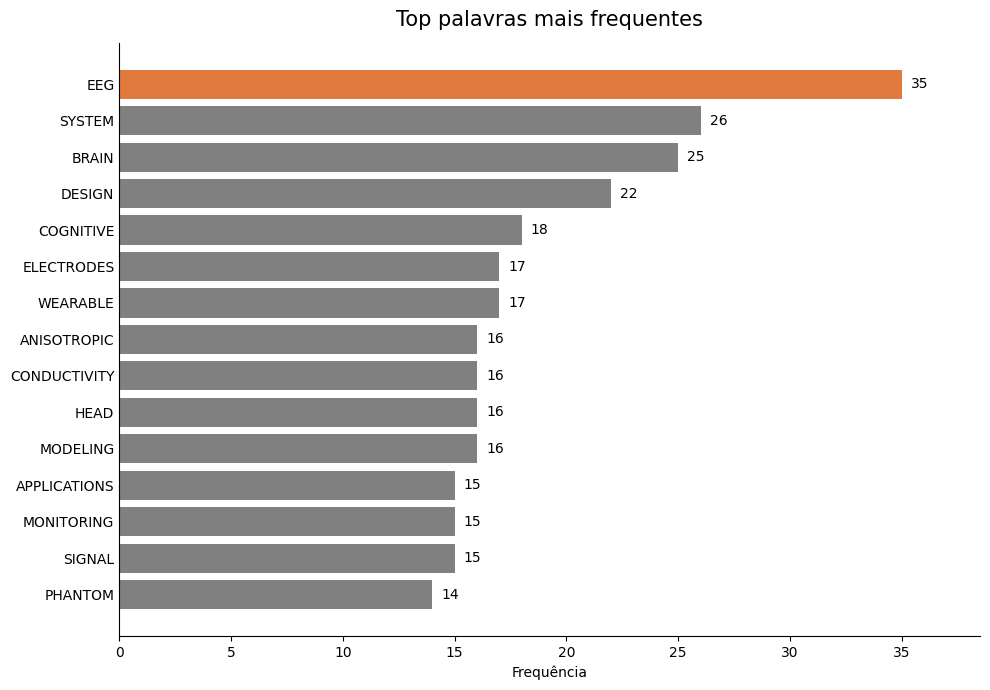

In [18]:
# Gráfico de barras: palavras mais frequentes

top_n = 15
top = sorted(frequencias.items(), key=lambda kv: kv[1], reverse=True)[:top_n]

# Inverte para a palavra mais frequente ficar no topo do gráfico horizontal
palavras = [p for p, _ in top][::-1]
valores = [v for _, v in top][::-1]

# Cores: cinza para todas e laranja para a palavra mais frequente
cores = ["grey"] * len(palavras)
cores[-1] = "#E07A3D"

fig, ax = plt.subplots(figsize=(10, 7))
barras = ax.barh(palavras, valores, color=cores)

# Valor ao final de cada barra
for barra, valor in zip(barras, valores):
    ax.text(barra.get_width() + 0.4, barra.get_y() + barra.get_height() / 2,
            str(valor), va="center", fontsize=10)

ax.set_title(f"Top palavras mais frequentes", fontsize=15, pad=12)
ax.set_xlabel("Frequência")
ax.set_xlim(0, max(valores) * 1.1)
ax.spines[["top", "right"]].set_visible(False)
ax.tick_params(axis="y", length=0)

plt.tight_layout()
plt.savefig("figs/topico_07_02_02.png", dpi=300, bbox_inches="tight", facecolor=plt.gcf().get_facecolor())
plt.show()

# Paleta de Cores

A biblioteca ainda permite mudar a paleta de cores utilizada na nuvem, também foi utilizada uma paleta diferente nas demais versões que ainda serão apresentadas nesse notebook, com o objetivo de demonstrar a variabilidade de paletas

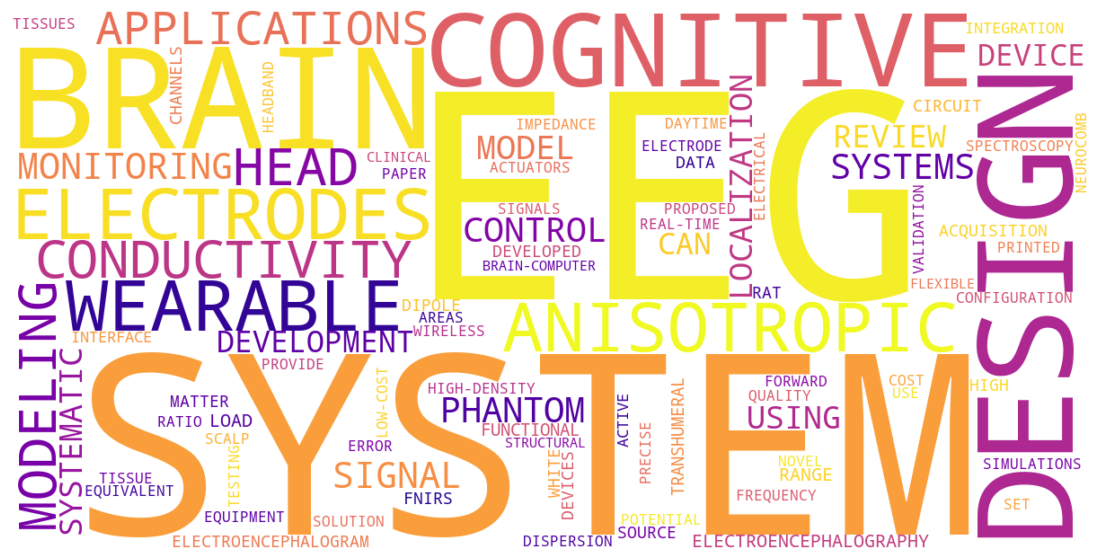

In [19]:
# Mudando a paleta de cores

nuvem_cores = WordCloud(
    width=1200,
    height=600,
    background_color="white",
    colormap="plasma",
    max_words=100
).generate_from_frequencies(frequencias)

plt.figure(figsize=(14, 7))
plt.imshow(nuvem_cores, interpolation="bilinear")
plt.axis("off")
plt.savefig("figs/topico_07_02_03.png", dpi=300, bbox_inches="tight", facecolor=plt.gcf().get_facecolor())
plt.show()

# Limitando a quantidade de palavras que aparecem na nuvem

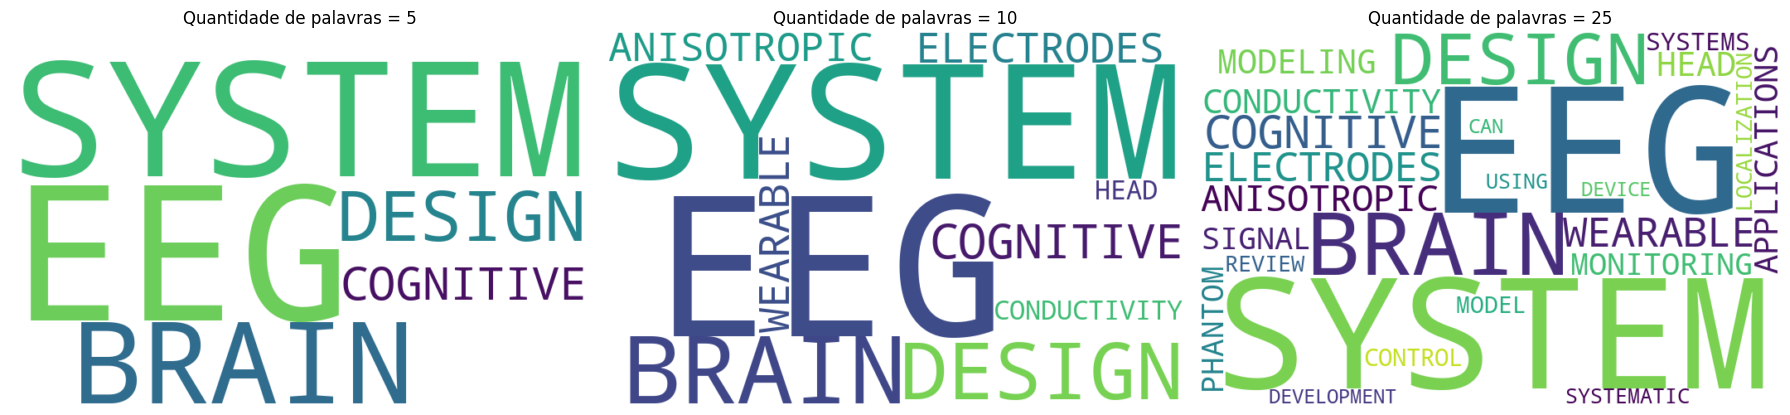

In [20]:
# Controlando o número de palavras

fig, eixos = plt.subplots(1, 3, figsize=(18, 6))
for ax, limite in zip(eixos, [5, 10, 25]):
    nuvem = WordCloud(
        width=700, height=450,
        background_color="white",
        colormap="viridis",
        max_words=limite
    ).generate_from_frequencies(frequencias)
    ax.imshow(nuvem, interpolation="bilinear")
    ax.set_title(f"Quantidade de palavras = {limite}")
    ax.axis("off")

plt.tight_layout()
plt.savefig("figs/topico_07_02_04.png", dpi=300, bbox_inches="tight", facecolor=plt.gcf().get_facecolor())
plt.show()

# Controlando o tamanho máximo e mínimo das fontes

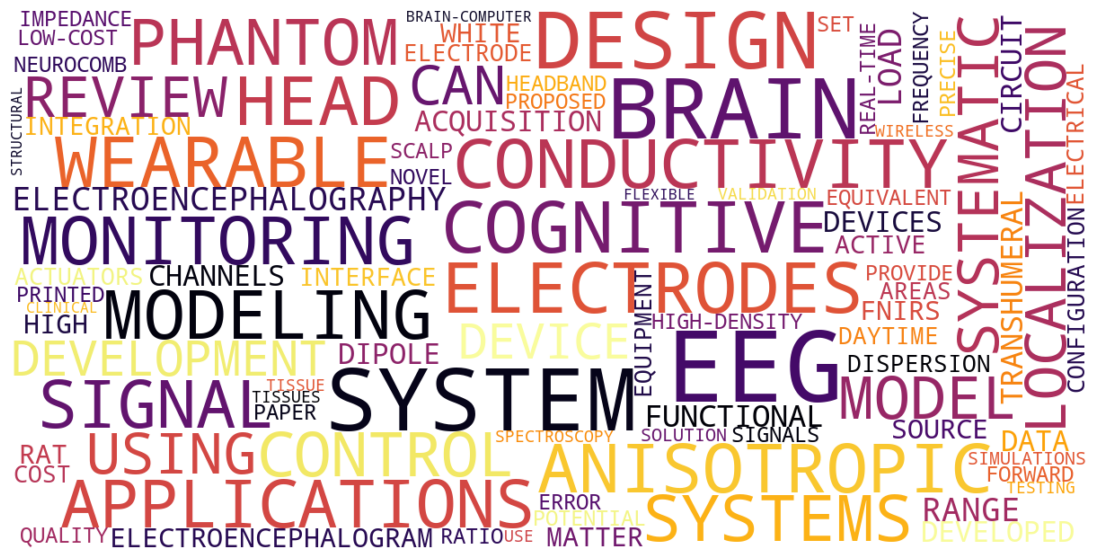

In [21]:
# Controlando o tamanho das fontes

nuvem_fontes = WordCloud(
    width=1200,
    height=600,
    background_color="white",
    colormap="inferno",
    min_font_size=8,
    max_font_size=110
).generate_from_frequencies(frequencias)

plt.figure(figsize=(14, 7))
plt.imshow(nuvem_fontes, interpolation="bilinear")
plt.axis("off")
plt.savefig("figs/topico_07_02_05.png", dpi=300, bbox_inches="tight", facecolor=plt.gcf().get_facecolor())
plt.show()

# Controlando a escala relativa e a margem

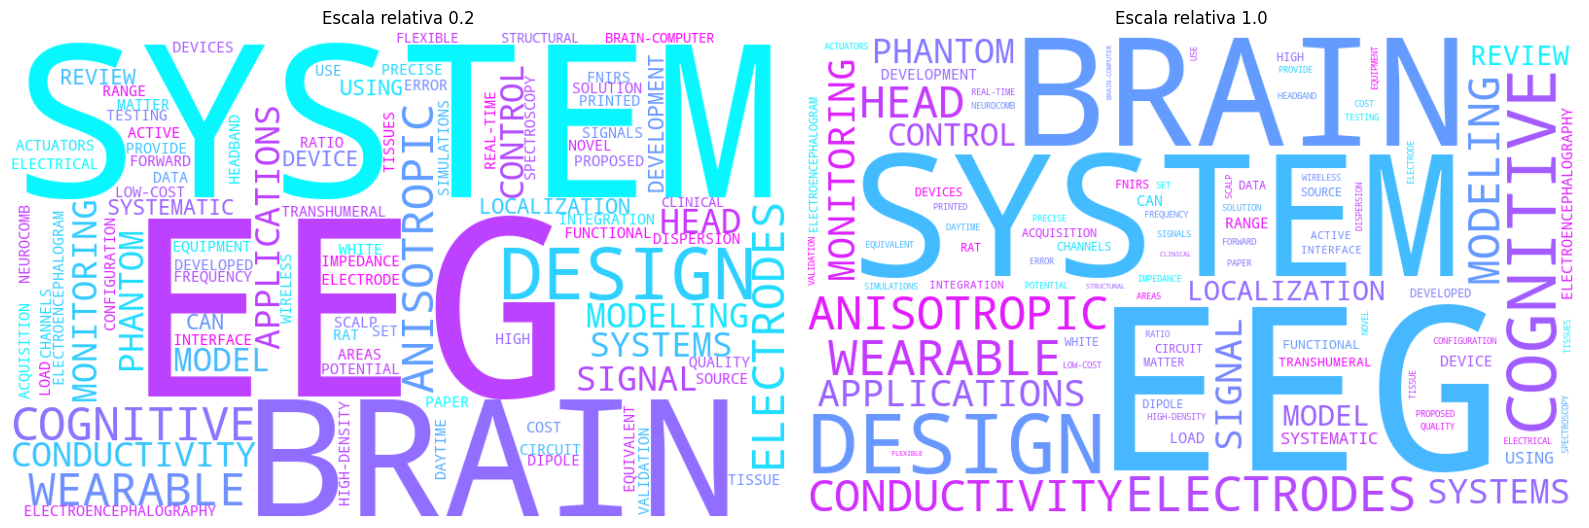

In [22]:
# Controlando a escala relativa e a margem

fig, eixos = plt.subplots(1, 2, figsize=(16, 6))
configuracoes = [
    {"relative_scaling": 0.2, "margin": 2, "title": "Escala relativa 0.2"},
    {"relative_scaling": 1.0, "margin": 12, "title": "Escala relativa 1.0"}
]

for ax, cfg in zip(eixos, configuracoes):
    nuvem = WordCloud(
        width=800, height=500,
        background_color="white",
        colormap="cool",
        relative_scaling=cfg["relative_scaling"],
        margin=cfg["margin"]
    ).generate_from_frequencies(frequencias)
    ax.imshow(nuvem, interpolation="bilinear")
    ax.set_title(cfg["title"])
    ax.axis("off")

plt.tight_layout()
plt.savefig("figs/topico_07_02_06.png", dpi=300, bbox_inches="tight", facecolor=plt.gcf().get_facecolor())
plt.show()

# Controlando a orientação das palavras

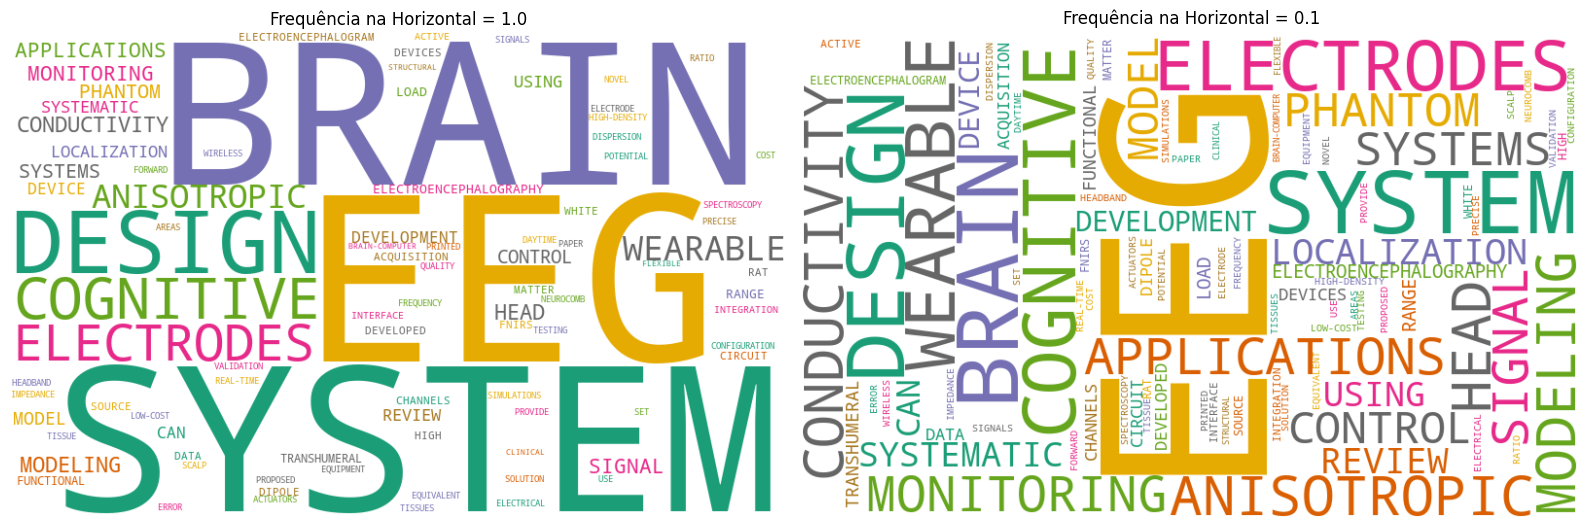

In [23]:
# Controlando a orientação das palavras

fig, eixos = plt.subplots(1, 2, figsize=(16, 6))
for ax, preferencia in zip(eixos, [1.0, 0.1]):
    nuvem = WordCloud(
        width=800, height=500,
        background_color="white",
        colormap="Dark2",
        prefer_horizontal=preferencia,
        random_state=12
    ).generate_from_frequencies(frequencias)
    ax.imshow(nuvem, interpolation="bilinear")
    ax.set_title(f"Frequência na Horizontal = {preferencia}")
    ax.axis("off")

plt.tight_layout()
plt.savefig("figs/topico_07_02_07.png", dpi=300, bbox_inches="tight", facecolor=plt.gcf().get_facecolor())
plt.show()

# Nuvem circular

Também é possível modificar o formato da nuvem, como exemplo, foi construída uma nuvem em formato circular

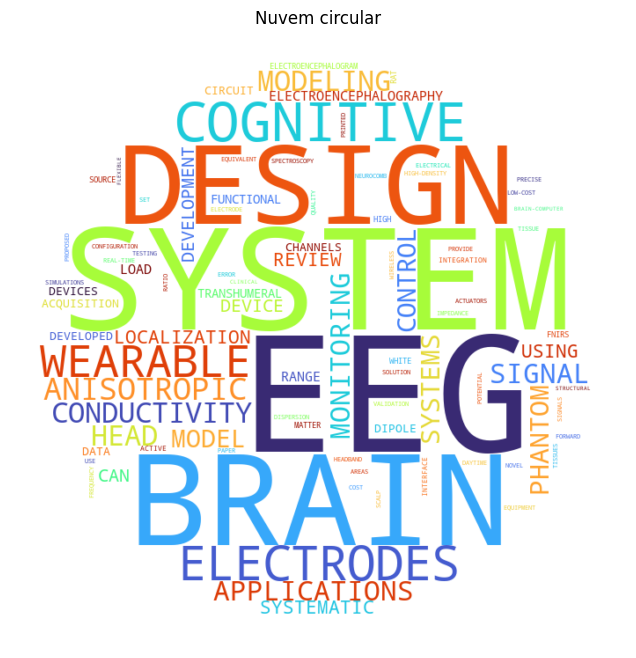

In [24]:
altura, largura = 700, 700
y, x = np.ogrid[:altura, :largura]
centro = (altura / 2, largura / 2)
raio = 320

distancia = (y - centro[0])**2 + (x - centro[1])**2
mascara_circular = np.where(distancia <= raio**2, 0, 255).astype(np.uint8)

nuvem_circular = WordCloud(
    width=largura,
    height=altura,
    mask=mascara_circular,
    background_color="white",
    colormap="turbo",
    random_state=42
).generate_from_frequencies(frequencias)

plt.figure(figsize=(8, 8))
plt.imshow(nuvem_circular, interpolation="bilinear")
plt.axis("off")
plt.title("Nuvem circular")
plt.savefig("figs/topico_07_02_08.png", dpi=300, bbox_inches="tight", facecolor=plt.gcf().get_facecolor())
plt.show()

# Nuvem por grupo

Também é possível pegar um conjunto de palavras e separar em grupos menores

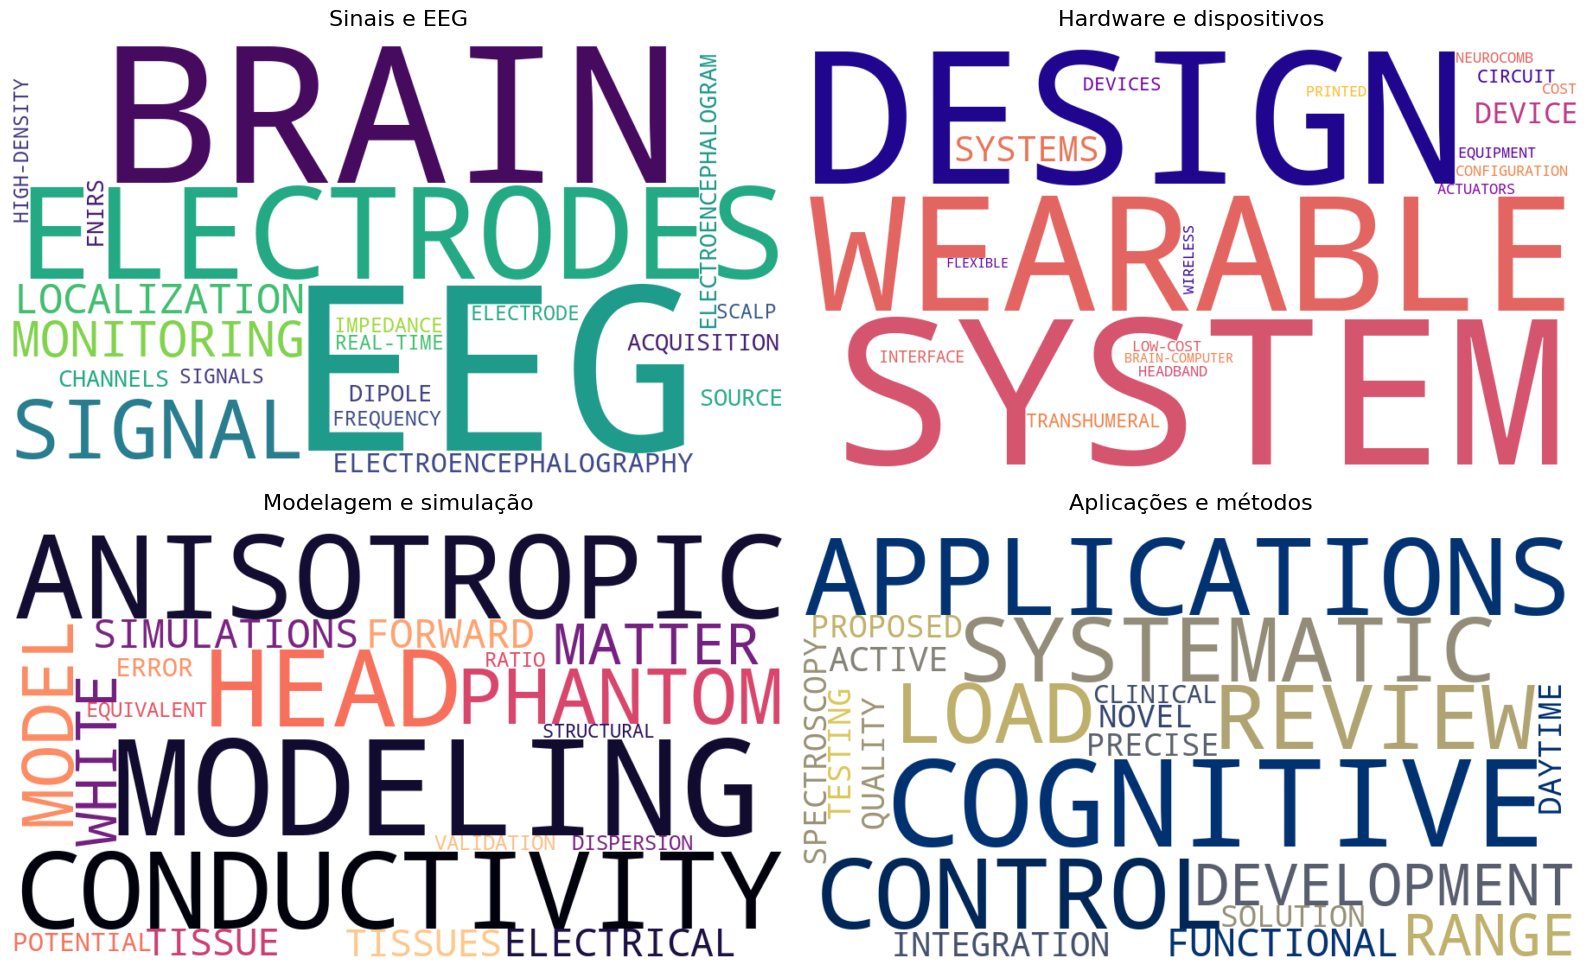

In [25]:
termos_por_grupo = {
    "Sinais e EEG": {
        "EEG": 35,
        "BRAIN": 25,
        "ELECTRODES": 17,
        "SIGNAL": 15,
        "MONITORING": 15,
        "ELECTROENCEPHALOGRAPHY": 10,
        "ACQUISITION": 8,
        "CHANNELS": 8,
        "ELECTROENCEPHALOGRAM": 8,
        "FNIRS": 8,
        "SOURCE": 8,
        "DIPOLE": 8,
        "LOCALIZATION": 11,
        "FREQUENCY": 6,
        "IMPEDANCE": 6,
        "SCALP": 6,
        "SIGNALS": 6,
        "REAL-TIME": 6,
        "ELECTRODE": 6,
        "HIGH-DENSITY": 6,
    },

    "Hardware e dispositivos": {
        "SYSTEM": 26,
        "DESIGN": 22,
        "WEARABLE": 17,
        "DEVICE": 10,
        "SYSTEMS": 14,
        "DEVICES": 8,
        "CIRCUIT": 8,
        "HEADBAND": 6,
        "WIRELESS": 6,
        "LOW-COST": 6,
        "COST": 6,
        "PRINTED": 6,
        "FLEXIBLE": 5,
        "INTERFACE": 7,
        "BRAIN-COMPUTER": 5,
        "ACTUATORS": 6,
        "EQUIPMENT": 6,
        "TRANSHUMERAL": 9,
        "CONFIGURATION": 6,
        "NEUROCOMB": 6,
    },

    "Modelagem e simulação": {
        "MODELING": 16,
        "ANISOTROPIC": 16,
        "CONDUCTIVITY": 16,
        "HEAD": 16,
        "PHANTOM": 14,
        "MODEL": 12,
        "SIMULATIONS": 6,
        "FORWARD": 6,
        "ELECTRICAL": 6,
        "TISSUE": 6,
        "TISSUES": 6,
        "MATTER": 8,
        "WHITE": 8,
        "POTENTIAL": 6,
        "ERROR": 6,
        "VALIDATION": 6,
        "EQUIVALENT": 6,
        "DISPERSION": 6,
        "STRUCTURAL": 5,
        "RATIO": 6,
    },

    "Aplicações e métodos": {
        "COGNITIVE": 18,
        "APPLICATIONS": 15,
        "CONTROL": 13,
        "LOAD": 10,
        "REVIEW": 11,
        "SYSTEMATIC": 11,
        "DEVELOPMENT": 10,
        "FUNCTIONAL": 9,
        "INTEGRATION": 7,
        "CLINICAL": 5,
        "DAYTIME": 6,
        "SPECTROSCOPY": 6,
        "ACTIVE": 7,
        "NOVEL": 6,
        "PROPOSED": 6,
        "TESTING": 6,
        "QUALITY": 6,
        "PRECISE": 6,
        "SOLUTION": 6,
        "RANGE": 10,
    },
}

# Uma nuvem de palavras para cada grupo semântico
quantidade_grupos = len(termos_por_grupo)
colunas = 2
linhas = (quantidade_grupos + colunas - 1) // colunas

fig, eixos = plt.subplots(linhas, colunas, figsize=(16, 5 * linhas))
eixos = np.array(eixos).reshape(-1)

paletas = [
    "viridis", "plasma", "magma", "cividis",
    "coolwarm", "Set2", "Dark2", "turbo"
]

for indice, (grupo, marcas) in enumerate(termos_por_grupo.items()):
    nuvem = WordCloud(
        width=900,
        height=500,
        background_color="white",
        colormap=paletas[indice % len(paletas)],
        max_words=50,
        prefer_horizontal=0.9,
        relative_scaling=0.6,
        random_state=42
    ).generate_from_frequencies(marcas)

    eixos[indice].imshow(nuvem, interpolation="bilinear")
    eixos[indice].set_title(grupo, fontsize=16, pad=12)
    eixos[indice].axis("off")

# Remove os espaços de eixos que não foram utilizados
for indice in range(len(termos_por_grupo), len(eixos)):
    eixos[indice].axis("off")

plt.tight_layout()
plt.savefig("figs/topico_07_02_09.png", dpi=300, bbox_inches="tight", facecolor=plt.gcf().get_facecolor())
plt.show()

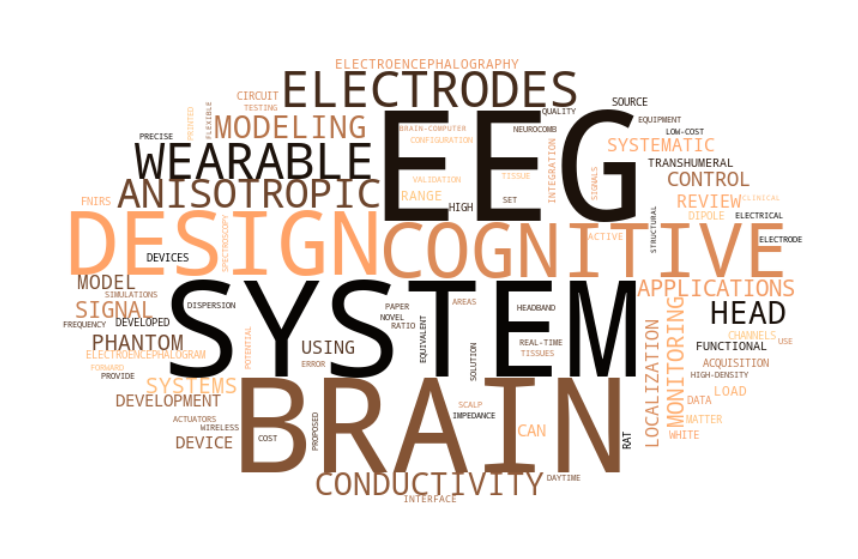

In [26]:
altura, largura = 450, 700
y, x = np.ogrid[:altura, :largura]

centro_y = altura / 2
centro_x = largura / 2

raio_y = 190
raio_x = 320

# Máscara elíptica horizontal
distancia = ((y - centro_y) / raio_y)**2 + ((x - centro_x) / raio_x)**2

mascara_eliptica = np.where(distancia <= 1, 0, 255).astype(np.uint8)

nuvem_eliptica = WordCloud(
    width=largura,
    height=altura,
    mask=mascara_eliptica,
    background_color="white",
    colormap="copper",
    random_state=42
).generate_from_frequencies(frequencias)

plt.figure(figsize=(12, 7))
plt.imshow(nuvem_eliptica, interpolation="bilinear")
plt.axis("off")
plt.savefig("figs/topico_07_02_10.png", dpi=300, bbox_inches="tight", facecolor=plt.gcf().get_facecolor())
plt.show()

# Palavras específicas

O objetivo desse gráfico assim como a nuvem de palavras é indicar a frequencia em que as palavras aparecem nos artigos avaliados pela revisão de literatura. Ele busca ser amis informativo indicando melhor o valor no qual a palavra se repete mas sem especificar individualmente. as cores indicam os grupoa aos quais as palavras pertencem, os bins se definem em intervalos onde as palavras acima se encaixam e a ordem das palavras empilhadas é definida pelo numero de repetições, quanto mais abaixo mais próximo do valor minimo daquele bin

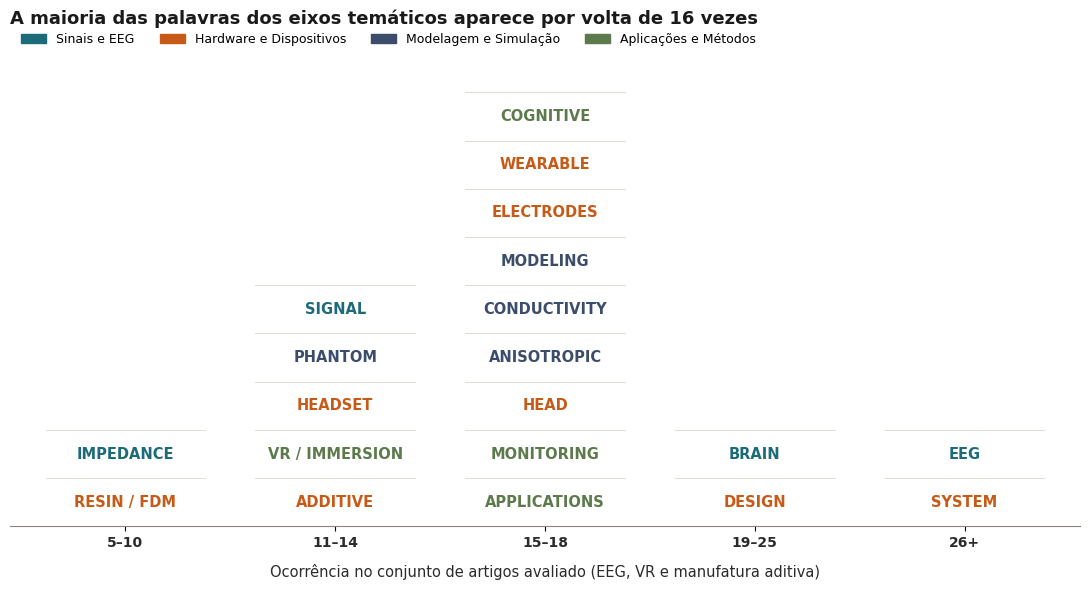

In [27]:
# 1. Palavras e frequencia organizadas por grupo
termos_por_grupo = {
    "Sinais e EEG": {
        "EEG": 35,
        "BRAIN": 25,
        "SIGNAL": 14,
        "IMPEDANCE": 10,
    },
    "Hardware e Dispositivos": {
        "SYSTEM": 26,
        "DESIGN": 22,
        "ELECTRODES": 17,
        "WEARABLE": 17,
        "HEAD": 16,
        "HEADSET": 12,
        "ADDITIVE": 11,
        "RESIN / FDM": 9,
    },
    "Modelagem e Simulação": {
        "ANISOTROPIC": 16,
        "CONDUCTIVITY": 16,
        "MODELING": 16,
        "PHANTOM": 13,
    },
    "Aplicações e Métodos": {
        "COGNITIVE": 18,
        "APPLICATIONS": 15,
        "MONITORING": 15,
        "VR / IMMERSION": 11,
    },
}

# Organiza os termos em (palavra, peso, categoria)
dados_palavras = [
    (palavra, peso, categoria)
    for categoria, termos in termos_por_grupo.items()
    for palavra, peso in termos.items()
]

paleta = {
    "Sinais e EEG": "#1B6B7A",
    "Hardware e Dispositivos": "#C85A17",
    "Modelagem e Simulação": "#3B4D6B",
    "Aplicações e Métodos": "#5C7A4B",
}

# 2. Definir bins no eixo X
bins = [(5, 11), (11, 15), (15, 19), (19, 26), (26, 40)]
rotulos_bins = ["5–10", "11–14", "15–18", "19–25", "26+"]

# Agrupar palavras por faixa
colunas = {label: [] for label in rotulos_bins}
for palavra, peso, cat in dados_palavras:
    for (low, high), label in zip(bins, rotulos_bins):
        if low <= peso < high:
            colunas[label].append((palavra, peso, cat))
            break

# Ordenar de baixo para cima
for label in rotulos_bins:
    colunas[label].sort(key=lambda item: item[1])

# 3. Plotar gráfico de palavras específicas
fig, ax = plt.subplots(figsize=(11, 6), facecolor="white")
ax.set_facecolor("white")

x_positions = np.arange(len(rotulos_bins))
espacamento_y = 0.42  # distância vertical entre palavras

for x_idx, label in enumerate(rotulos_bins):
    itens = colunas[label]
    for y_idx, (palavra, peso, cat) in enumerate(itens):
        y_pos = (y_idx + 0.5) * espacamento_y
        ax.text(
            x_idx,
            y_pos,
            palavra,
            ha="center",
            va="center",
            fontsize=10.5,
            fontweight="bold",
            color=paleta[cat],
        )
        # Linha horizontal separando cada palavra
        ax.plot(
            [x_idx - 0.38, x_idx + 0.38],
            [y_pos + espacamento_y / 2, y_pos + espacamento_y / 2],
            color="#E2DDD5",
            linewidth=0.8,
        )

# Configuração dos eixos
ax.set_xticks(x_positions)
ax.set_xticklabels(rotulos_bins, fontsize=10, fontweight="bold", color="#2B2B2B")
ax.set_xlim(-0.55, len(rotulos_bins) - 0.45)

max_itens = max((len(v) for v in colunas.values()), default=1)
ax.set_ylim(0, (max_itens + 0.6) * espacamento_y)
ax.set_yticks([])

# Remover bordas superiores e laterais
for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)
ax.spines["bottom"].set_color("#8C857B")

# Títulos e legenda
ax.set_xlabel(
    "Ocorrência no conjunto de artigos avaliado (EEG, VR e manufatura aditiva)",
    fontsize=10.5,
    labelpad=10,
    color="#2B2B2B",
)
ax.set_title(
    "A maioria das palavras dos eixos temáticos aparece por volta de 16 vezes",
    loc="left",
    fontsize=13,
    fontweight="bold",
    pad=28,
    color="#1A1A1A",
)

legendas = [mpatches.Patch(color=cor, label=cat) for cat, cor in paleta.items()]
ax.legend(
    handles=legendas,
    frameon=False,
    ncol=4,
    loc="upper left",
    bbox_to_anchor=(0, 1.09),
    fontsize=9,
)

plt.tight_layout()
plt.savefig("figs/topico_07_02_11.png", dpi=300, bbox_inches="tight")
plt.show()